# Monthly temperature trends, 1901-2017
Long-run warming in a national monthly mean-temperature series: tidy reshaping, seasonal profile, **trend estimation with uncertainty**, and a decade-by-decade comparison of how each month has changed.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import statsmodels.api as sm
wide = pd.read_csv("data/monthly_temperature.csv", index_col=0)
months = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]
t = wide.melt(id_vars="YEAR", value_vars=months, var_name="month", value_name="temp")
t["date"] = pd.to_datetime(t.month + " " + t.YEAR.astype(str), format="%b %Y"); t = t.sort_values("date").set_index("date")
print(f"{len(t):,} monthly observations, {t.YEAR.min()}-{t.YEAR.max()}")

1,404 monthly observations, 1901-2017


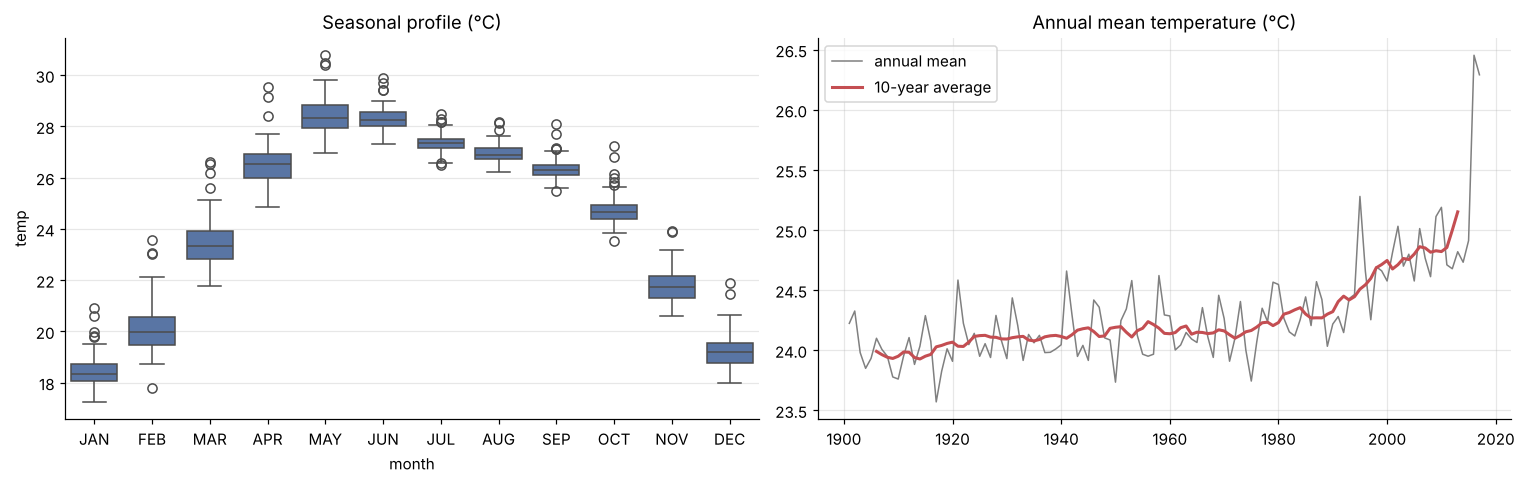

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=t, x="month", y="temp", ax=ax[0], color="#4C72B0"); ax[0].set_title("Seasonal profile (°C)")
annual = t.groupby("YEAR").temp.mean()
ax[1].plot(annual, color="grey", lw=1, label="annual mean"); ax[1].plot(annual.rolling(10, center=True).mean(), color="#C44E52", lw=2, label="10-year average")
ax[1].set_title("Annual mean temperature (°C)"); ax[1].legend()
fig.tight_layout(); plt.savefig(IMG / "temperature_overview.png", bbox_inches="tight"); plt.show()

In [3]:
# Linear trend with Newey-West (HAC) standard errors, robust to autocorrelation
def trend(y):
    X = sm.add_constant((y.index - y.index[0]) / 100)       # per century
    res = sm.OLS(y.values, X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    return float(res.params[1]), np.asarray(res.conf_int())[1]
rows = {"Full period 1901-2017": trend(annual), "1901-1960": trend(annual.loc[:1960]), "1961-2017": trend(annual.loc[1961:])}
pd.DataFrame({k: {"trend (°C per century)": v[0], "95% CI low": v[1][0], "95% CI high": v[1][1]} for k, v in rows.items()}).T.round(2)

,trend (°C per century),95% CI low,95% CI high
Full period 1901-2017,0.84,0.52,1.16
1901-1960,0.41,0.17,0.65
1961-2017,2.22,1.42,3.03


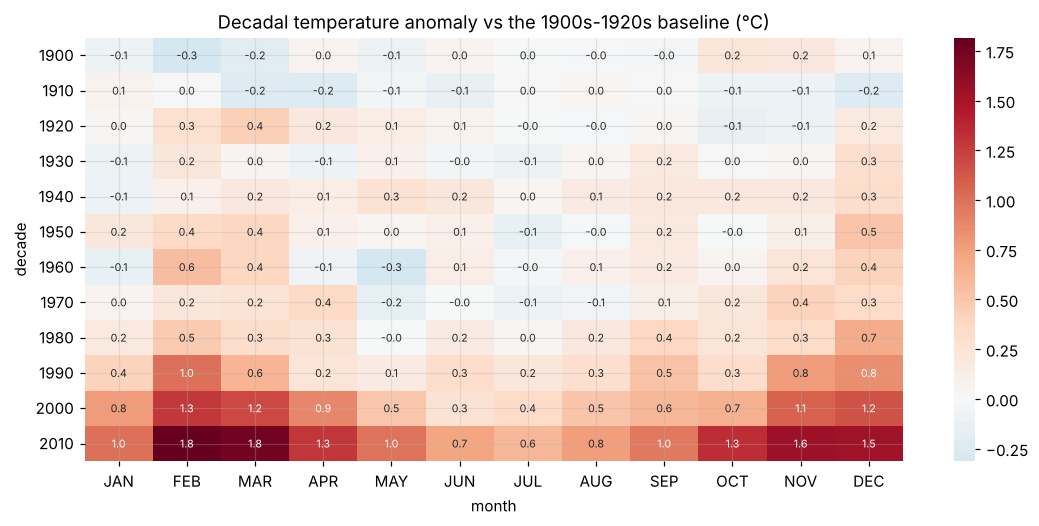

In [4]:
dec = t.assign(decade=(t.YEAR // 10) * 10).pivot_table(index="decade", columns="month", values="temp")[months]
anom = dec - dec.loc[1901:1930].mean() if 1901 in dec.index else dec - dec.iloc[:3].mean()
plt.figure(figsize=(12, 5)); sns.heatmap(anom, cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Decadal temperature anomaly vs the 1900s-1920s baseline (°C)"); plt.savefig(IMG / "decadal_anomaly.png", bbox_inches="tight"); plt.show()

**Findings:** the warming trend is statistically significant even with autocorrelation-robust standard errors, and it **accelerates after 1960**. The anomaly heatmap shows that warming is not uniform across the year: some months have warmed far more than others, which matters for agriculture, energy demand and other seasonal planning.